# Brazil business survival: what the data can actually tell us
**A national registry profile and a separate, published longitudinal benchmark.**

This notebook asks three questions: What businesses are registered in Brazil in the October 2026 CNPJ release? How do current administrative status and composition differ by state, industry and opening cohort? What can we responsibly say about five-year survival?

The two evidence streams answer different questions. CNPJ is a current administrative snapshot of registered establishments and legal entities, including public bodies and nonprofits as well as commercial businesses. IBGE follows a 2017 cohort of **employer enterprises** through 2022; its state tables concern **employer local units**. An active registration is not proof of uninterrupted trading, employment, or survival. No individual CNPJ survival model is fitted here.

Run all cells from this project directory or from the repository root. Inputs are the complete national aggregate and original-source IBGE extracts. The earlier 60,000-row preview is nonrepresentative and is excluded from national estimates.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
from importlib import metadata

ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'story.json').exists():
    ROOT = ROOT / 'projects' / 'brazil-business-survival'
assert (ROOT / 'research' / 'analysis.py').exists(), 'Run from the project or repository root.'
FIGURES = ROOT / 'assets' / 'notebook'
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.facecolor':'#faf8f0', 'axes.facecolor':'#faf8f0',
    'axes.spines.top':False, 'axes.spines.right':False, 'axes.labelcolor':'#153d31',
    'text.color':'#153d31', 'font.size':11, 'axes.titleweight':'bold',
    'savefig.facecolor':'#faf8f0', 'figure.dpi':120})
GREEN, YELLOW = '#153d31', '#d8ab2e'
def finish(fig, name, source, unit):
    fig.text(.02, .015, unit + '\nSource: ' + source, fontsize=8, color='#53645a')
    fig.tight_layout(rect=(0,.09,1,1))
    fig.savefig(FIGURES / (name + '.png'), dpi=180, bbox_inches='tight')
    plt.show()
def read_json(path):
    return json.loads(path.read_text(encoding='utf-8'))

In [2]:
runtime_versions = {'python':sys.version}
for package in ['duckdb','pyarrow','pandas','numpy','matplotlib','nbformat','nbclient','openpyxl','requests']:
    try:
        runtime_versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        runtime_versions[package] = 'not installed'
display(pd.Series(runtime_versions,name='Runtime versions').to_frame())
(ROOT / 'data' / 'runtime-versions.json').write_text(json.dumps(runtime_versions,indent=2)+'\n',encoding='utf-8')

,Runtime versions
python,"3.13.1 (tags/v3.13.1:0671451, Dec 3 2024, 19:..."
duckdb,1.4.4
pyarrow,19.0.0
pandas,2.3.3
numpy,2.4.3
matplotlib,3.10.1
nbformat,5.10.4
nbclient,0.11.0
openpyxl,3.1.5
requests,2.33.0


305

## Reproducibility and source inventory
The local acquisition scripts document official URLs, release selection and file provenance. CNPJ processing reads all ten Empresas archives and all ten Estabelecimentos archives, rather than treating one ZIP or a row prefix as a national sample. Partner (Sócios) and MEI/Simples tax-option files are inventoried but are not processed in this aggregation; no owner-level, MEI-specific or tax-regime conclusions follow. Raw archives and Parquet working files are intentionally ignored by Git; the checked-in aggregates keep this notebook practical to execute.

Acquisition is an explicit, potentially large operation. This notebook never downloads files implicitly. To reproduce from scratch, follow the commands in README.md, retain the provenance manifests, build the full aggregate, then run this notebook. Re-execution of this notebook requires only aggregate JSON files, pandas, NumPy and Matplotlib; full processing has additional dependencies described in the README.

In [3]:
# Optional rebuild from already acquired local data; deliberately off by default.
REBUILD_LOCAL_AGGREGATES = False
if REBUILD_LOCAL_AGGREGATES:
    get_ipython().run_line_magic('run', str(ROOT / 'research' / 'analysis.py'))

story = read_json(ROOT / 'data' / 'story.json')
ibge = read_json(ROOT / 'data' / 'ibge' / 'survival.json')
# Local helper import without assuming a notebook launch directory.
analysis_namespace = {'__name__': 'notebook_analysis', '__file__': str(ROOT / 'research' / 'analysis.py')}
exec(compile((ROOT / 'research' / 'analysis.py').read_text(encoding='utf-8'), 'analysis.py', 'exec'), analysis_namespace)
validate_story = analysis_namespace['validate_story']
survival_feasibility = analysis_namespace['survival_feasibility']
validate_story(story)
assert story['meta']['survival_model_identified'] is False
assert ibge['national']['births'] == 261302
assert ibge['local_units_national']['births'] == 296850
assert sum(r['births'] for r in ibge['states']) == 296850
display(pd.Series(story['meta'], name='CNPJ release metadata').to_frame())
display(pd.DataFrame(story['meta']['sources']))
manifest = read_json(ROOT / 'data' / 'source-manifest.json')
assert len(manifest) == 20, 'National analysis requires all 20 source archives.'
assert {r['archive'] for r in manifest} == {f'{group}{i}.zip' for group in ['Empresas','Estabelecimentos'] for i in range(10)}
assert all(r['complete_archive_crc_checked'] for r in manifest)
display(pd.DataFrame(manifest)[['archive','release','rows','source_bytes','source_sha256','retrieved_at_utc','complete_archive_crc_checked']])
display(pd.DataFrame.from_dict(read_json(ROOT / 'data' / 'reference-manifest.json'),orient='index'))
display(pd.json_normalize(read_json(ROOT / 'data' / 'archive-triage.json')).T)
display(pd.DataFrame(ibge['sources']))
inventory = read_json(ROOT / 'data' / 'source-inventory.json')
display(pd.Series({k:v for k,v in inventory.items() if not isinstance(v,list)}, name='inventory metadata').to_frame())
for key, value in inventory.items():
    if isinstance(value, list):
        print(f'{key}: {len(value):,} records; first 8 shown')
        display(pd.DataFrame(value).head(8))

,CNPJ release metadata
release,2026-10
retrieved_on,2026-10-20
scope,Complete national CNPJ snapshot: all ten compa...
survival_model_identified,False
sources,[{'label': 'Receita Federal CNPJ source files'...
archive_count,20
source_compressed_bytes,6803481897
population_note,CNPJ covers registered legal entities and esta...
geography_note,Current registered location; includes EX (outs...
cohort_note,Opening-year composition of retained registrat...


,label,url
0,Receita Federal CNPJ source files,https://arquivos.receitafederal.gov.br/index.p...
1,Official CNPJ layout,https://www.gov.br/receitafederal/dados/cnpj-m...
2,Pipeline reference,https://github.com/caiopizzol/cnpj-data-pipeline


,archive,release,rows,source_bytes,source_sha256,retrieved_at_utc,complete_archive_crc_checked
0,Empresas1.zip,2026-10,4494860,77901368,226713337ad77b876be58d7ac9cc92a7d9144f57809915...,2026-10-19T15:59:44.241117+00:00,True
1,Empresas2.zip,2026-10,4494860,79125712,d9ab5e05dd156bca6c207db7651c46e675600659c43015...,2026-10-19T15:59:58.684082+00:00,True
2,Empresas3.zip,2026-10,4494860,85102880,5b360ae214d61bc1392e053cc76dc751154e5d379ae962...,2026-10-19T16:03:24.165532+00:00,True
3,Empresas4.zip,2026-10,4494860,90222463,7f7b726b0394112ee39bdda4e16b1a409cdd17dcadb255...,2026-10-19T16:03:41.672444+00:00,True
4,Empresas6.zip,2026-10,4494860,94194819,9260ac6e25b6b11651fcf4b09ab57a03c2e9940edee459...,2026-10-19T16:03:47.078518+00:00,True
5,Empresas9.zip,2026-10,4494860,94309858,366f667afb46474d040b9823217a092991b65e37cb3e62...,2026-10-19T16:03:40.072641+00:00,True
6,Empresas5.zip,2026-10,4494860,97310075,356cd0b1d33226204059054a4c59ef6a704fb8f68e182f...,2026-10-19T16:03:49.082300+00:00,True
7,Empresas7.zip,2026-10,4494860,98676055,cacf2f5e184191aa6f5ced48c1ef727a745c343d73da5a...,2026-10-19T16:03:59.948888+00:00,True
8,Empresas8.zip,2026-10,4494860,98736571,2401492df8263624eef750e986d9e2e263a9f2b8802bf2...,2026-10-19T16:04:30.687374+00:00,True
9,Estabelecimentos5.zip,2026-10,4753435,335452647,4f333a7f08ac505b7192be8ddf11ae133df61865f97388...,2026-10-20T04:11:38.932158+00:00,True


,archive,release,source_url,source_bytes,sha256,verified_on,complete_archive_crc_checked
Cnaes.zip,Cnaes.zip,2026-10,https://arquivos.receitafederal.gov.br/public....,22078,e3cee921b7055c2f77ecb92ab328603ac2adb099f883a9...,2026-10-20,True
Naturezas.zip,Naturezas.zip,2026-10,https://arquivos.receitafederal.gov.br/public....,1585,c92728a7d9acc9535baa752a8fce1ebe100155909209df...,2026-10-20,True


,0
url,https://arquivos.receitafederal.gov.br/public....
bytes,63954782749
last_modified,"Wed, 28 Jan 2026 15:22:29 GMT"
inspection,Bounded HTTP range bytes=0-65535; first two ta...
first_members,"[{'name': '2025-05', 'type': 'directory'}, {'n..."
interpretation,A separate large bundle begins with monthly-re...
retrieved_on,2026-10-20


...

,inventory metadata
release,2026-10


directories: 44 records; first 8 shown


,path,bytes,last_modified
0,/public.php/webdav/,0,"Tue, 13 Oct 2026 22:09:31 GMT"
1,/public.php/webdav/2023-05/,0,"Tue, 20 May 2025 20:54:47 GMT"
2,/public.php/webdav/2023-06/,0,"Tue, 20 May 2025 20:54:47 GMT"
3,/public.php/webdav/2023-07/,0,"Tue, 20 May 2025 20:54:47 GMT"
4,/public.php/webdav/2023-08/,0,"Tue, 20 May 2025 20:54:47 GMT"
5,/public.php/webdav/2023-09/,0,"Tue, 20 May 2025 20:54:47 GMT"
6,/public.php/webdav/2023-10/,0,"Tue, 20 May 2025 20:54:46 GMT"
7,/public.php/webdav/2023-11/,0,"Tue, 20 May 2025 20:54:46 GMT"


files: 38 records; first 8 shown


,path,bytes,last_modified
0,/public.php/webdav/2026-10/,0,"Tue, 13 Oct 2026 22:09:31 GMT"
1,/public.php/webdav/2026-10/Cnaes.zip,22078,"Tue, 13 Oct 2026 22:00:16 GMT"
2,/public.php/webdav/2026-10/Empresas0.zip,570972127,"Tue, 13 Oct 2026 22:00:54 GMT"
3,/public.php/webdav/2026-10/Empresas1.zip,77901368,"Tue, 13 Oct 2026 22:01:01 GMT"
4,/public.php/webdav/2026-10/Empresas2.zip,79125712,"Tue, 13 Oct 2026 22:01:07 GMT"
5,/public.php/webdav/2026-10/Empresas3.zip,85102880,"Tue, 13 Oct 2026 22:01:14 GMT"
6,/public.php/webdav/2026-10/Empresas4.zip,90222463,"Tue, 13 Oct 2026 22:01:21 GMT"
7,/public.php/webdav/2026-10/Empresas5.zip,97310075,"Tue, 13 Oct 2026 22:01:28 GMT"


## National registry profile
**Unit:** CNPJ establishments for administrative status, geography, primary industry and opening date; company entities for legal size and capital. Branches and headquarters belong to the establishment population. Registered companies are not interchangeable with establishments or with IBGE employer enterprises.

Counts below describe the release, not a probability sample. “Active share” divides current active registrations by all registrations in the displayed group; it is not a survival estimate. Retained closed registrations affect this denominator. Any missing or invalid classifications must remain visible in the quality checks.

,National registry counts and active share
establishments,7.380938e+07
active,2.838065e+07
headquarters,7.051744e+07
branches,3.291941e+06
companies,7.051744e+07
company_source_records,7.051744e+07
active_share,3.845128e-01
domestic_establishments,7.363597e+07
domestic_active,2.829935e+07
domestic_active_share,3.843142e-01


,code,count,label,share
0,08,34829938,Deregistered,0.471890
1,02,28380653,Active,0.384513
2,04,10165173,Unfit,0.137722
3,03,323068,Suspended,0.004377
4,01,110547,Null registration,0.001498


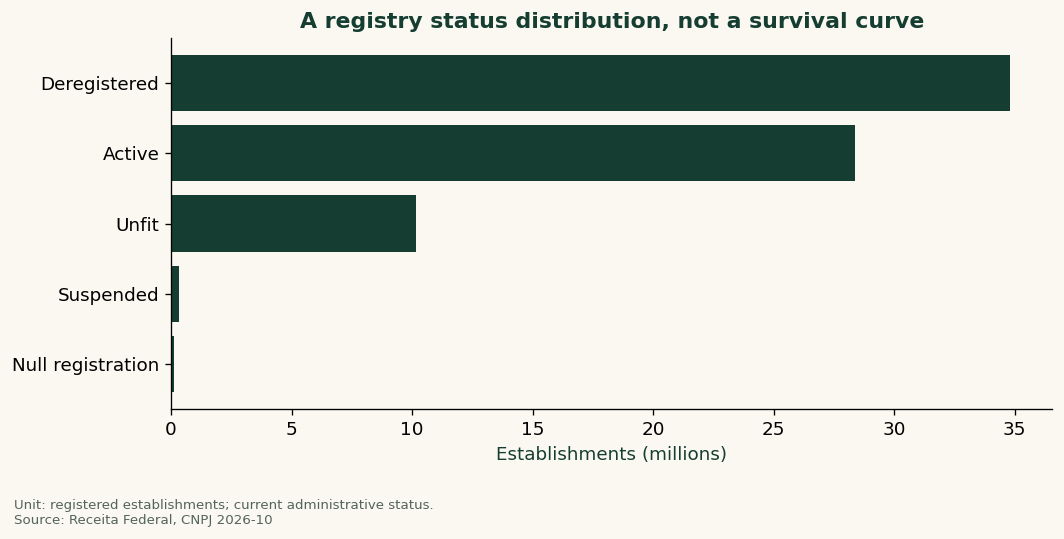

In [4]:
national = story['national']
display(pd.Series(national, name='National registry counts and active share').to_frame())
statuses = pd.DataFrame(story['statuses'])
display(statuses)
fig, ax = plt.subplots(figsize=(9,4.5))
s = statuses.sort_values('count')
ax.barh(s['label'], s['count']/1e6, color=GREEN)
ax.set(xlabel='Establishments (millions)', title='A registry status distribution, not a survival curve')
finish(fig, 'registry-status', 'Receita Federal, CNPJ '+str(story['meta']['release']), 'Unit: registered establishments; current administrative status.')

## Geography: scale and current status
The all-register national totals include EX (outside Brazil) and any unknown geography. The domestic comparator restricts to the 26 Brazilian states plus the Federal District (27 UFs): `domestic_establishments`, `domestic_active` and `domestic_active_share`. `outside_or_unknown_geography` records the excluded establishment count. Use the domestic active share for the Brazilian UF map/comparison; use all-register counts to reconcile the full source release. The table below retains every geography category.

The largest registered populations naturally dominate counts. Comparing active shares changes the question from scale to administrative composition. Neither comparison adjusts for opening year, industry, legal form, registration practices or headquarters/branch structure. State differences cannot establish a location effect or support a causal “best state” recommendation.

,uf,total,active,headquarters,branches,name,active_share
0,SP,21369926,8833181,20346062,1023864,São Paulo,0.413346
1,MG,7988006,2935399,7661468,326538,Minas Gerais,0.367476
2,RJ,6253182,2299466,6026569,226613,Rio de Janeiro,0.367727
3,PR,5029433,2018638,4811265,218168,Paraná,0.401365
4,RS,5015901,1761594,4769234,246667,Rio Grande do Sul,0.351202
5,BA,3634418,1271841,3475346,159072,Bahia,0.349944
6,SC,3607531,1558584,3428690,178841,Santa Catarina,0.432036
7,GO,2675945,1055499,2572469,103476,Goiás,0.394440
8,PE,2202846,744715,2101456,101390,Pernambuco,0.338069
9,CE,2095032,757799,2008923,86109,Ceará,0.361712


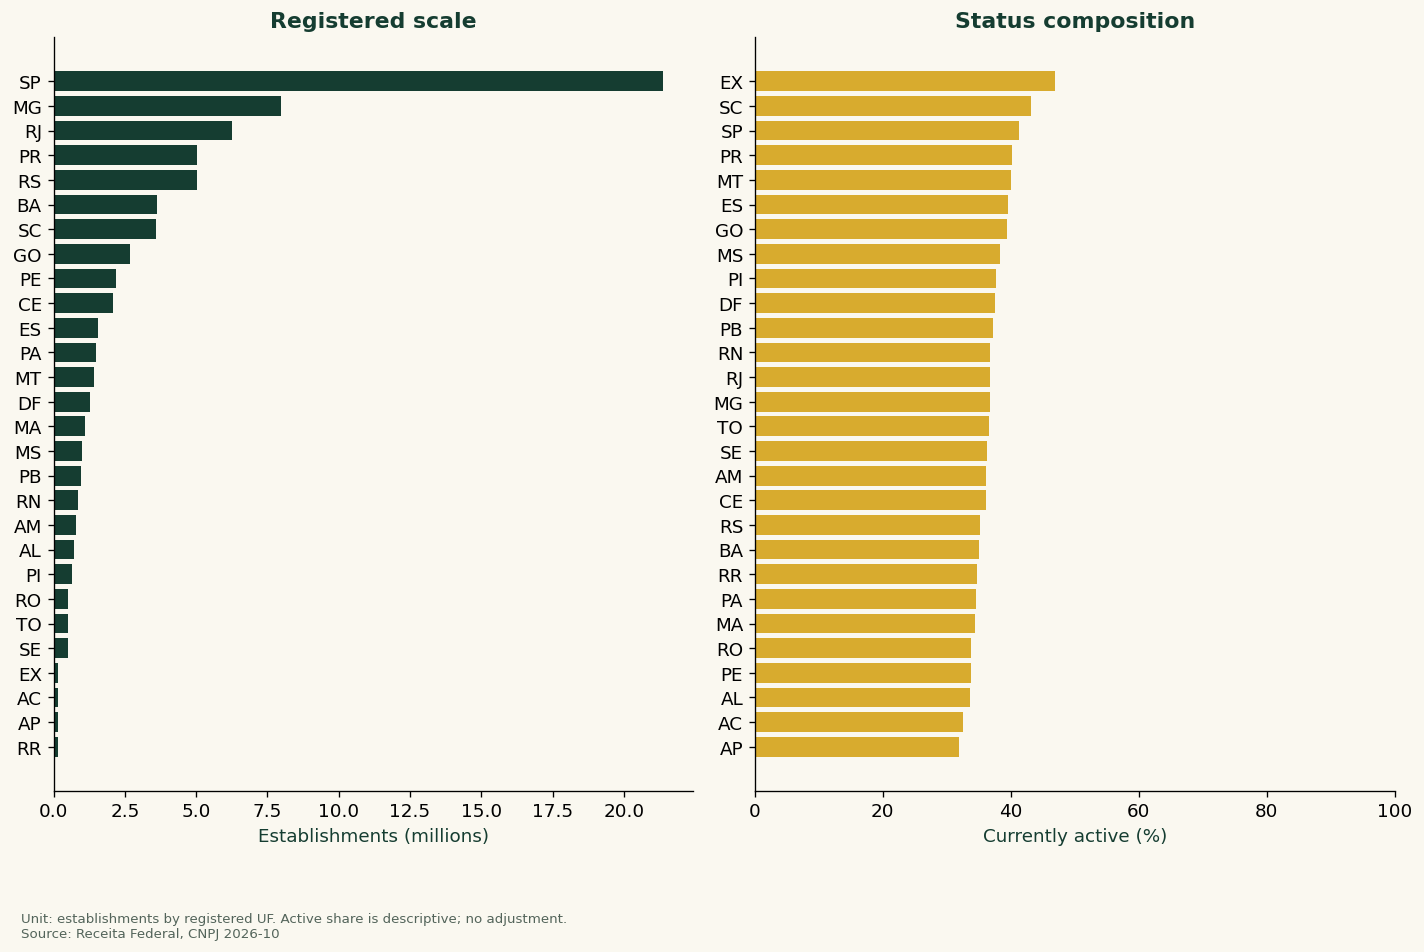

In [5]:
states = pd.DataFrame(story['states'])
display(states.sort_values('total', ascending=False))
fig, axes = plt.subplots(1,2,figsize=(12,8))
s = states.sort_values('total')
axes[0].barh(s['uf'], s['total']/1e6, color=GREEN)
axes[0].set(xlabel='Establishments (millions)', title='Registered scale')
s = states.sort_values('active_share')
axes[1].barh(s['uf'], s['active_share']*100, color=YELLOW)
axes[1].set(xlabel='Currently active (%)', title='Status composition', xlim=(0,100))
finish(fig, 'registry-states', 'Receita Federal, CNPJ '+str(story['meta']['release']), 'Unit: establishments by registered UF. Active share is descriptive; no adjustment.')

## Primary industry and opening cohorts
Industry is the establishment's registered primary activity; secondary activities are not additional businesses. The table retains the aggregate's industry coding level and labels. Older opening cohorts have had more opportunity to close, but also face changes in registry coverage and record retention. Cohort active shares mix period, cohort and administrative effects. They must not be plotted or described as observed age-specific survival probabilities.

,code,total,active,label,active_share
0,4781400,3739346,1014303,Comércio varejista de artigos do vestuário e a...,0.271251
1,9492800,3326186,158594,Atividades de organizações políticas,0.047680
2,5611203,2061351,475233,"Lanchonetes, casas de chá, de sucos e similares",0.230544
3,9602501,2044079,942603,"Cabeleireiros, manicure e pedicure",0.461138
4,7319002,1880659,839779,Promoção de vendas,0.446534
...,...,...,...,...,...
1338,1822900,2,0,Serviços de acabamentos gráficos,0.000000
1339,3091100,2,2,"Fabricação de motocicletas, peças e acessórios",1.000000
1340,9609201,2,0,Clinicas de estética e similares,0.000000
1341,5611202,1,0,Bares e outros estabelecimentos especializados...,0.000000


,year,total,active,active_share
0,1891,1,1,1.000000
1,1893,1,1,1.000000
2,1899,2,2,1.000000
3,1901,161,147,0.913043
4,1902,3,3,1.000000
...,...,...,...,...
124,2022,3977694,1904203,0.478720
125,2023,3985063,2419239,0.607077
126,2024,4844307,2649108,0.546850
127,2025,5195568,3953407,0.760919


C:\Users\acrom\AppData\Local\Temp\ipykernel_22772\3275559815.py:22: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout(rect=(0,.09,1,1))


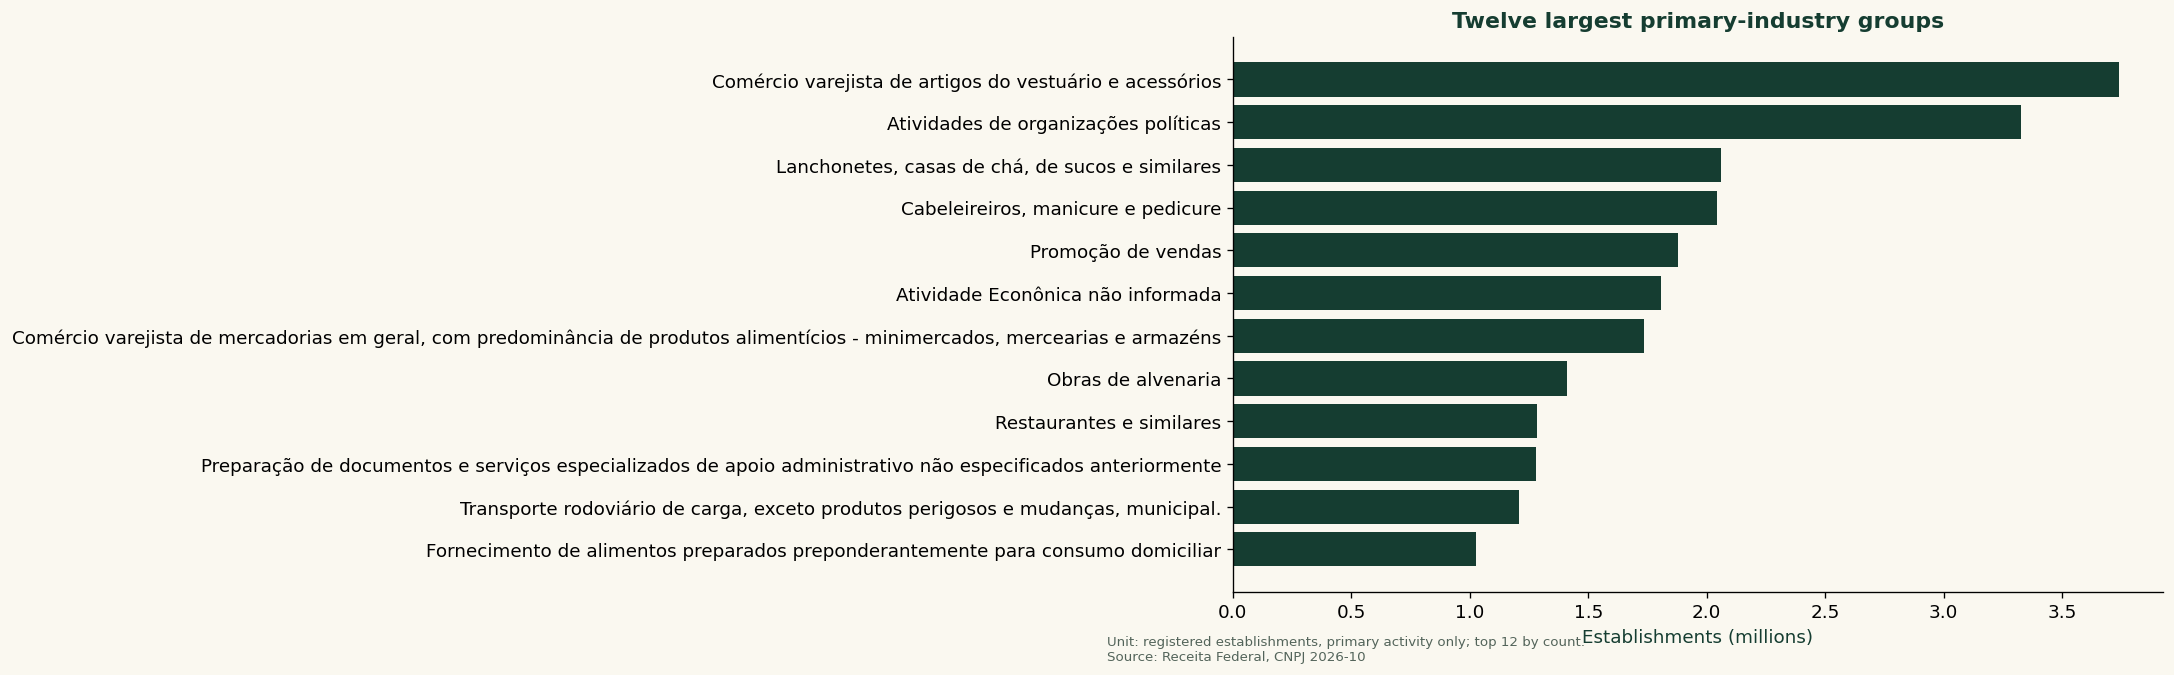

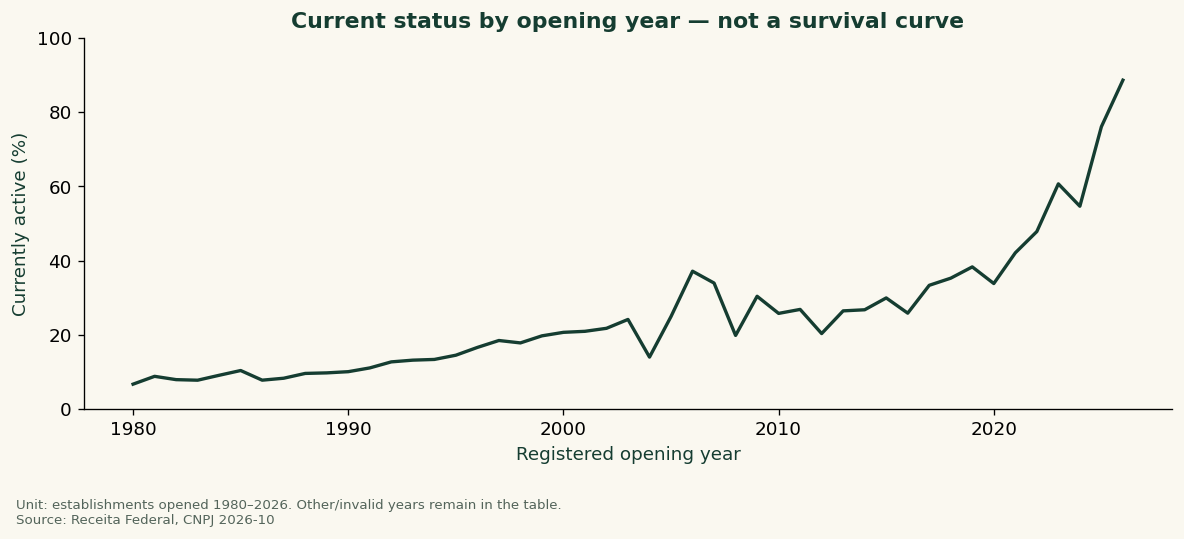

In [6]:
industries = pd.DataFrame(story['industries'])
cohorts = pd.DataFrame(story['cohorts'])
display(industries.sort_values('total', ascending=False))
display(cohorts.sort_values('year'))
fig, ax = plt.subplots(figsize=(10,6))
s = industries.nlargest(12,'total').sort_values('total')
ax.barh(s['label'], s['total']/1e6, color=GREEN)
ax.set(xlabel='Establishments (millions)', title='Twelve largest primary-industry groups')
finish(fig, 'registry-industries', 'Receita Federal, CNPJ '+str(story['meta']['release']), 'Unit: registered establishments, primary activity only; top 12 by count.')
fig, ax = plt.subplots(figsize=(10,4.5))
s = cohorts.copy()
s['numeric_year'] = pd.to_numeric(s['year'], errors='coerce')
s = s[s['numeric_year'].between(1980,2026)].sort_values('numeric_year')
ax.plot(s['numeric_year'], s['active_share']*100, color=GREEN, linewidth=2)
ax.set(xlabel='Registered opening year', ylabel='Currently active (%)', ylim=(0,100), title='Current status by opening year — not a survival curve')
finish(fig, 'registry-opening-cohorts', 'Receita Federal, CNPJ '+str(story['meta']['release']), 'Unit: establishments opened 1980–2026. Other/invalid years remain in the table.')

## Company size, capital and data quality
**Unit:** unique CNPJ roots after compatible-profile normalisation; original company source rows and duplicate-resolution diagnostics remain separately reported. CNPJ size codes describe legal registration categories; they are not the salaried-personnel bands in IBGE. Declared share capital is an administrative amount, not revenue, employment, liquidity or inflation-adjusted operating scale. Its heavy tail makes the median and percentiles more useful than an unsupported “typical business” mean. Capital quantiles use successfully parsed, non-null values; missing amounts are excluded, while reported zeros and negative amounts remain included. Zero capital need not mean no economic activity.

Reconciliation checks are necessary but insufficient: totals can reconcile while records contain invalid dates or missing keys. The quality report below is part of the result, not a cleaning footnote. Review its exact denominators before interpreting rare groups or incomplete company matches.

Company profiles use **unique CNPJ roots**, while `national.company_source_records` retains the original source-record count. The full-source audit found 70,517,438 source rows and 70,517,437 distinct roots: one root had two profiles. The raw Parquet remains unchanged. Normalisation merges only compatible reported values across duplicate profiles; legal-nature `0000` and size `00`/missing are treated as unreported, while zero capital remains a valid reported value. Genuine conflicting reported values become null and are flagged, rather than choosing a row arbitrarily. The quality report distinguishes duplicate root groups, excess source rows, ambiguous profiles and any remaining duplicate roots. Unique-root company totals and profiles therefore reconcile independently of establishment totals.

The declared capital value `999999999999` is flagged as a suspected sentinel/extreme value, not silently removed or proven erroneous. `suspected_sentinel_999999999999` reports its count. Quantiles retain it, along with zeros and negative values, so readers can assess the administrative field's limitations; these amounts are not validated economic valuations.

In [7]:
display(pd.DataFrame(story['company_profile']['size']))
display(pd.DataFrame(story['company_profile']['legal_forms']).sort_values('count',ascending=False))
display(pd.Series(story['company_profile']['capital'], name='Declared company capital (BRL)').to_frame())
display(pd.json_normalize(story.get('quality', {})).T.rename(columns={0:'value'}))
quality_rows = []
for key, value in story.get('quality', {}).items():
    if isinstance(value, int) and not isinstance(value, bool):
        denominator = national['company_source_records'] if key == 'duplicate_company_source_records' else national['companies'] if 'company' in key else national['establishments']
        quality_rows.append({'diagnostic':key,'count':value,'denominator':denominator,'share_pct':100*value/denominator})
display(pd.DataFrame(quality_rows))
validate_story(story)
print('National dimension reconciliations passed.')

,code,count,label
0,01,53422438,Microenterprise
1,05,14927587,Other
2,03,2163300,Small enterprise
3,Unknown,4112,Unknown


,code,count,label
0,2135,45727417,Empresário (Individual)
1,2062,16866279,Sociedade Empresária Limitada
2,4090,2958486,Candidato a Cargo Político Eletivo
3,3999,1436578,Associação Privada
4,2240,810093,Sociedade Simples Limitada
...,...,...,...
86,1163,3,Órgão Público Autônomo Federal
87,2275,3,Empresa Binacional
88,1287,1,Fundo Público da Administração Indireta Federal
89,1350,1,ENTIDADE PÚBLICA SOB REGIME ESPECIAL


,Declared company capital (BRL)
n,7.051744e+07
zero,1.759553e+07
negative,0.000000e+00
missing,0.000000e+00
suspected_sentinel_999999999999,1.240000e+02
median,1.500000e+03
p90,5.000000e+04
p99,5.228370e+05
max,1.000000e+12
valid_n,7.051744e+07


,value
missing_or_invalid_opening_date,0
missing_or_invalid_status_date,115377
status_date_before_opening,1065
opening_date_after_retrieval,0
status_date_after_retrieval,0
malformed_cnpj_base,0
min_opening_date,1891-10-23
max_opening_date,2026-10-11
min_status_date,1899-10-16
max_status_date,2026-10-11


,diagnostic,count,denominator,share_pct
0,missing_or_invalid_opening_date,0,73809379,0.000000
1,missing_or_invalid_status_date,115377,73809379,0.156318
2,status_date_before_opening,1065,73809379,0.001443
3,opening_date_after_retrieval,0,73809379,0.000000
4,status_date_after_retrieval,0,73809379,0.000000
5,malformed_cnpj_base,0,73809379,0.000000
6,unmatched_cnae_records,0,73809379,0.000000
7,missing_establishment_keys,0,73809379,0.000000
8,duplicate_establishment_keys,0,73809379,0.000000
9,duplicate_company_keys,1,70517437,0.000001


National dimension reconciliations passed.


## Can these CNPJ files identify five-year survival?
No. The verified monthly directories span May 2023 to October 2026: **41 months between release endpoints**, shorter than a 60-month follow-up. This describes the inspected monthly directory coverage, not a claim that older data cannot exist elsewhere. A separate 63.95 GB TAR received bounded header inspection (recorded in `data/archive-triage.json`); its inspected first member headers point to May 2025. This is triage evidence, not an exhaustive catalogue of its contents or proof of a longer observation history. The TAR was not silently treated as a longitudinal dataset. Downloading those verified monthly snapshots cannot manufacture five years of observation. A current opening date plus current active status does not show continuous activity. A current closure/status date does not recover all earlier transitions, temporary inactivity or reactivation.

A defensible individual survival design would first require a longitudinal population definition, observable entry, repeated status histories, explicit event and censoring rules, deduplication and a full follow-up window. The current work supplies none of the evidence needed to claim a fitted or calibrated individual five-year model. The published IBGE cohort below is an external descriptive benchmark with its own population, not a calibration target for all CNPJs.

In [8]:
feasibility = survival_feasibility('2023-05','2026-10',horizon_years=5)
assert feasibility['observed_months'] == 41
assert feasibility['identified'] is False
display(pd.Series(feasibility, name='Five-year identification audit').to_frame())

,Five-year identification audit
identified,False
observed_months,41
required_months,60
reason,Available releases span fewer than five years;...


## The official five-year benchmark: employer enterprises
IBGE Table 2.1 follows **261,302 employer-enterprise births in 2017** through 2018–2022. An employer enterprise has at least one salaried employee at year end. Employer births also include qualifying reactivations and entry into employer status. Survival requires remaining an employer in every consecutive observation year: losing employer status can end survival without legal closure.

These are published aggregate percentages, not Kaplan–Meier estimates fitted here. The pandemic falls inside the follow-up period, but this curve alone cannot isolate its causal effect. No confidence intervals or reconstructed survivor counts are invented.

,age,year,survival_pct,published_value
0,1,2018,76.21603,76.21603
1,2,2019,59.63253,59.63253
2,3,2020,49.36434,49.36434
3,4,2021,42.27752,42.27752
4,5,2022,37.31889,37.31889


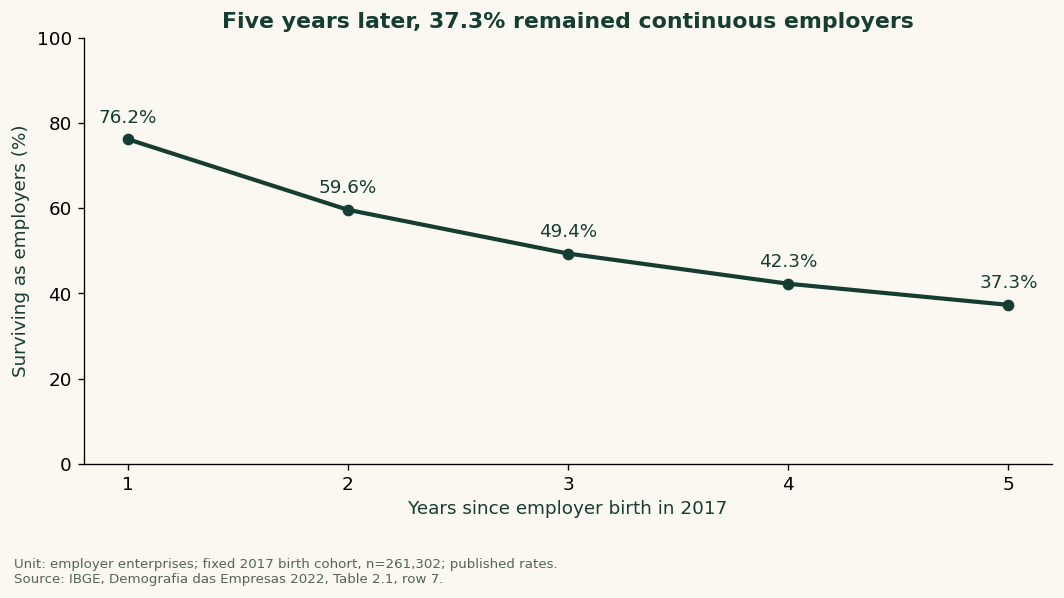

In [9]:
curve = pd.DataFrame(ibge['national_curve'])
display(curve)
fig, ax = plt.subplots(figsize=(9,5))
ax.plot(curve['age'], curve['survival_pct'], marker='o', color=GREEN, linewidth=2.5)
for row in curve.itertuples():
    ax.annotate(f'{row.survival_pct:.1f}%',(row.age,row.survival_pct),xytext=(0,10),textcoords='offset points',ha='center')
ax.set(xticks=curve['age'], xlabel='Years since employer birth in 2017', ylabel='Surviving as employers (%)', ylim=(0,100), title='Five years later, 37.3% remained continuous employers')
finish(fig, 'ibge-national-curve', 'IBGE, Demografia das Empresas 2022, Table 2.1, row 7.', 'Unit: employer enterprises; fixed 2017 birth cohort, n=261,302; published rates.')

## Employer enterprise sectors and size bands
Both comparisons use the enterprise population from Table 2.1. Display cohort denominators alongside rates: tiny groups can look extreme, and a rank does not establish a robust business opportunity. Sector composition, firm characteristics and size are associated; aggregate tables cannot disentangle them. Employee-size bands are the published group labels, not CNPJ legal size codes or a causal treatment.

The inspected Table 2.1 and publication do not explicitly document the size-classification reference year, so the bands are not asserted to be measurements at birth or baseline predictors. Zero-birth groups remain in the table but are omitted from the chart.

,label,births,five_year_survival_pct,source_table,source_row
0,"A Agricultura, pecuária, produção florestal, p...",2177,41.93845,2.1,13
1,B Indústrias extrativas,391,40.15345,2.1,14
2,C Indústrias de transformação,20925,42.27957,2.1,15
3,D Eletricidade e gás,119,57.98319,2.1,16
4,"E Água, esgoto, atividades de gestão de resídu...",739,42.21922,2.1,17
5,F Construção,17709,26.16749,2.1,18
6,G Comércio; reparação de veículos automotores ...,111520,37.01220,2.1,19
7,"H Transporte, armazenagem e correio",13748,34.25953,2.1,20
8,I Alojamento e alimentação,26776,30.57589,2.1,21
9,J Informação e comunicação,4793,43.83476,2.1,22


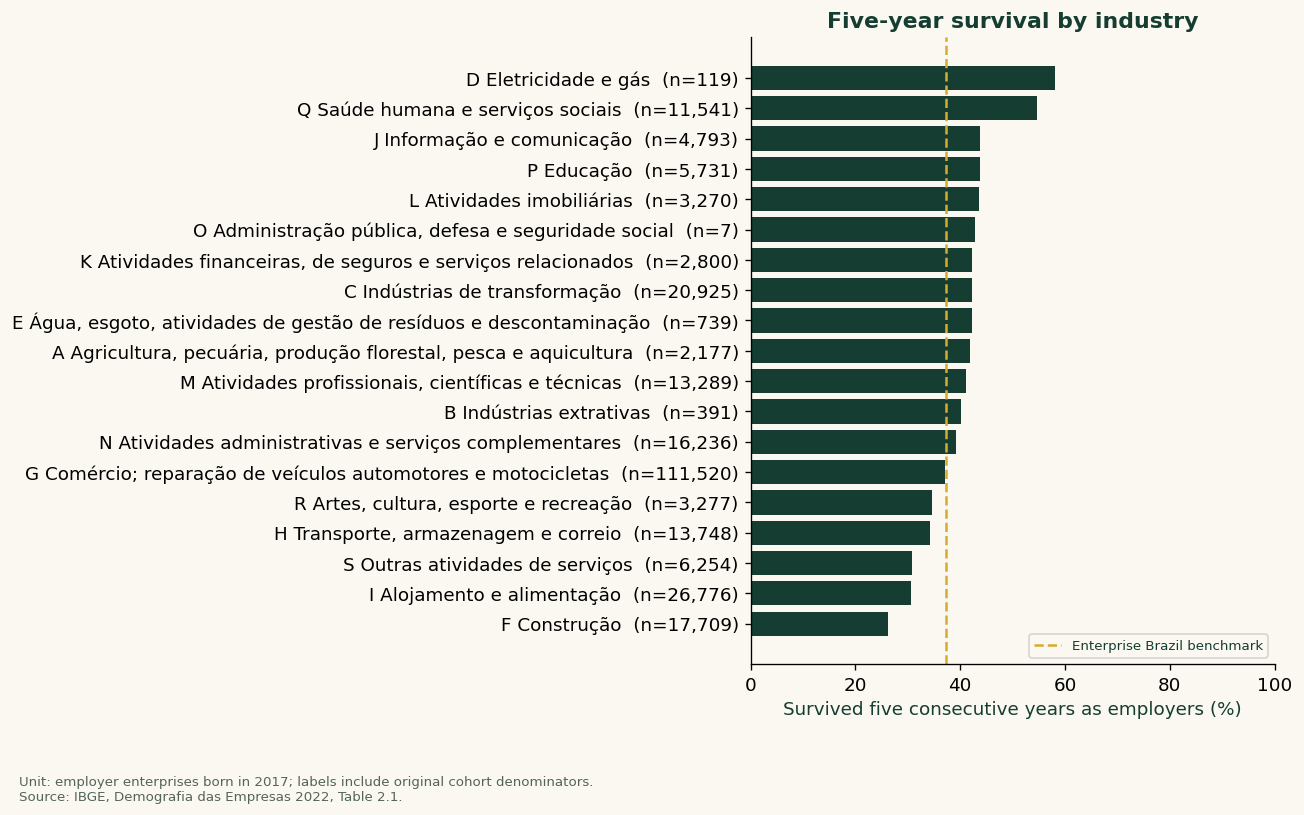

,label,births,five_year_survival_pct,source_table,source_row
0,1 a 9,242505,35.88091,2.1,9
1,10 a 49,17192,55.40368,2.1,10
2,50 ou mais,1605,60.87227,2.1,11


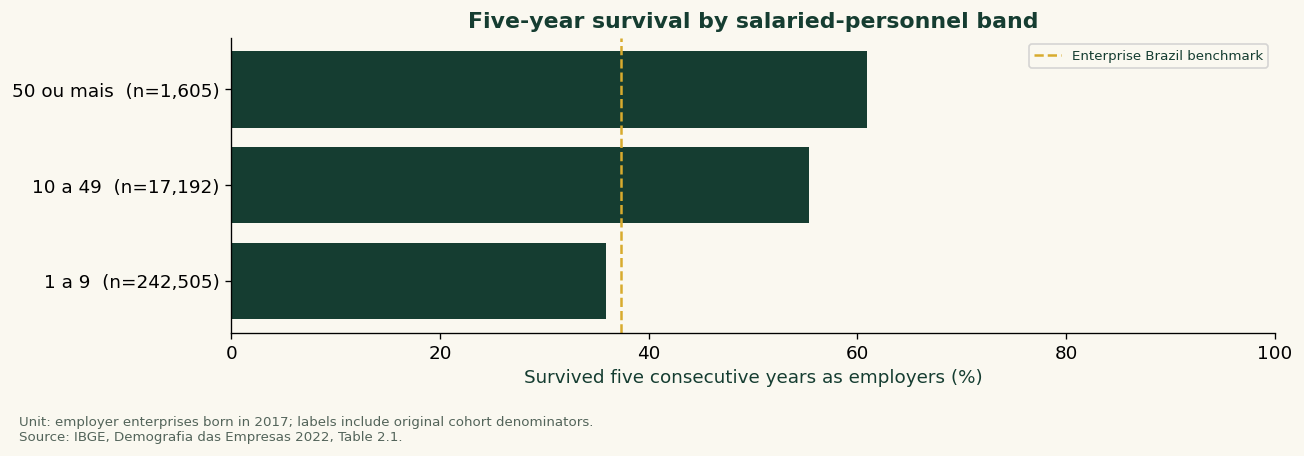

In [10]:
for key, title, filename in [('sectors','Five-year survival by industry','ibge-enterprise-sectors'),('sizes','Five-year survival by salaried-personnel band','ibge-enterprise-sizes')]:
    table = pd.DataFrame(ibge[key])
    display(table[['label','births','five_year_survival_pct','source_table','source_row']])
    # A published dash is exact zero, but a zero-birth group has no interpretable survival proportion.
    s = table[table['births'].gt(0) & table['five_year_survival_pct'].notna()].sort_values('five_year_survival_pct')
    fig, ax = plt.subplots(figsize=(11,max(3.8,len(s)*.36)))
    labels = [f"{r.label}  (n={r.births:,})" for r in s.itertuples()]
    ax.barh(labels,s['five_year_survival_pct'],color=GREEN)
    ax.axvline(ibge['national']['five_year_survival_pct'],color=YELLOW,linestyle='--',label='Enterprise Brazil benchmark')
    ax.set(xlabel='Survived five consecutive years as employers (%)',xlim=(0,100),title=title)
    ax.legend(fontsize=8)
    finish(fig, filename, 'IBGE, Demografia das Empresas 2022, Table 2.1.', 'Unit: employer enterprises born in 2017; labels include original cohort denominators.')

## State distribution: a different population
IBGE Table 2.2 concerns **employer local units**, not enterprises. Its Brazil cohort contains **296,850 local-unit births**, with 37.85% surviving five years. The appropriate state comparator is that local-unit Brazil rate, not the 37.32% enterprise rate. A multi-site enterprise may contribute several local units. Rankings are descriptive and unadjusted for industry or employer size; they do not identify a location effect.

The denominator-weighted state average should reproduce the published local-unit national rate, within workbook rounding. This is a reconciliation check, not adjustment or causal evidence.

,geography,births,five_year_survival_pct,source_table,source_row
14,Sergipe,2274,40.45734,2.2,363
11,Paraíba,3559,40.15173,2.2,300
21,Santa Catarina,17513,39.98173,2.2,552
8,Piauí,3009,39.91359,2.2,237
4,Pará,5940,38.97306,2.2,132
17,Espírito Santo,6186,38.94277,2.2,447
18,Rio de Janeiro,19597,38.64877,2.2,468
19,São Paulo,77841,38.48101,2.2,489
22,Rio Grande do Sul,20225,38.41286,2.2,573
7,Maranhão,4640,37.88793,2.2,216


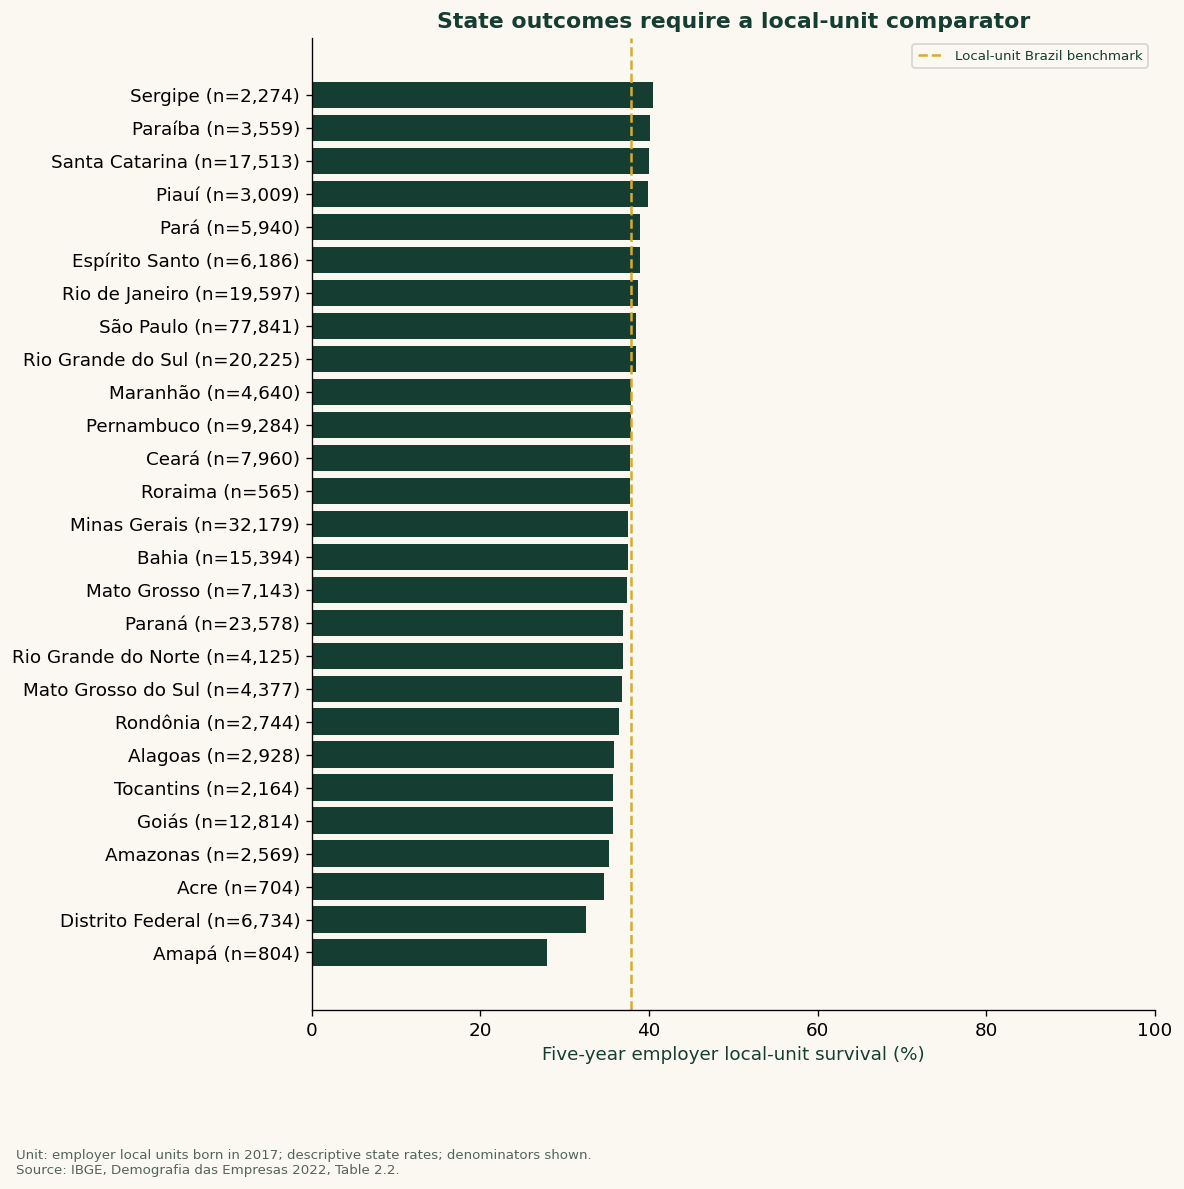

In [11]:
local_states = pd.DataFrame(ibge['states'])
display(local_states[['geography','births','five_year_survival_pct','source_table','source_row']].sort_values('five_year_survival_pct',ascending=False))
weighted = np.average(local_states['five_year_survival_pct'],weights=local_states['births'])
assert abs(weighted - ibge['local_units_national']['five_year_survival_pct']) < .00001
s = local_states.sort_values('five_year_survival_pct')
fig, ax = plt.subplots(figsize=(10,10))
ax.barh([f'{r.geography} (n={r.births:,})' for r in s.itertuples()],s['five_year_survival_pct'],color=GREEN)
ax.axvline(ibge['local_units_national']['five_year_survival_pct'],color=YELLOW,linestyle='--',label='Local-unit Brazil benchmark')
ax.set(xlabel='Five-year employer local-unit survival (%)',xlim=(0,100),title='State outcomes require a local-unit comparator')
ax.legend(fontsize=8)
finish(fig, 'ibge-local-unit-states', 'IBGE, Demografia das Empresas 2022, Table 2.2.', 'Unit: employer local units born in 2017; descriptive state rates; denominators shown.')

## Separating industry composition from the state comparison
The state × sector cells in IBGE Table 2.2 permit a **descriptive industry standardisation**. Restrict to sectors with positive cohort births in every state. For sector s, set the common national weight w_s = national births_s / total national births in included sectors. For each state j, the standardised rate is Σ_s w_s × published survival_pct_(j,s).

The same national weights in every state remove differences in the mix of included sectors from this arithmetic comparison. They do not adjust for employee size, firm age within entry definitions, ownership, municipality, selection or unobserved factors. The result is not an individual survival model, a causal location effect, or a forecast. The change from the state's raw common-support rate measures this particular reweighting, not an attributable cause.

The primary support covers 17 sectors and 99.9168% of national local-unit births. Electricity/gas and public administration are excluded because some states have no births; international bodies have no national births. Display both the full-population raw rate and the common-support raw rate so the support restriction is visible. Small positive state-sector denominators still make the standardised comparison fragile.

,Standardisation support
minimum_births_in_every_state_sector,1
national_common_births,296603
national_total_births,296850
national_cohort_coverage_pct,99.916793
national_common_five_year_pct,37.836434
method,Direct descriptive standardisation: sum over c...
scope,Employer local units only. Adjusts CNAE-sectio...
raw_common_method,State sector-birth-weighted average of publish...
rank_convention,Rank 1 is highest descriptive survival percent...


,section,national_weight_pct
0,A,0.869850
1,B,0.187119
2,C,7.668500
3,E,0.286578
4,F,6.132777
5,G,44.444931
6,H,5.332380
7,I,9.943932
8,J,1.808141
9,K,1.326015


,uf,name,full_births,common_births,state_cohort_coverage_pct,min_included_sector_births,raw_full_five_year_pct,raw_common_five_year_pct,standardised_five_year_pct,composition_shift_pp,rank_change_vs_raw_common
14,SE,Sergipe,2274,2272,99.912049,4,40.45734,40.404929,40.431909,0.026980,0
11,PB,Paraíba,3559,3559,100.000000,6,40.15173,40.151728,40.213885,0.062157,0
21,SC,Santa Catarina,17513,17497,99.908639,23,39.98173,39.972566,39.796231,-0.176335,0
8,PI,Piauí,3009,3009,100.000000,7,39.91359,39.913593,39.350918,-0.562675,0
18,RJ,Rio de Janeiro,19597,19579,99.908149,32,38.64877,38.628123,38.775424,0.147301,2
19,SP,São Paulo,77841,77775,99.915212,42,38.48101,38.457089,38.670268,0.213179,2
4,PA,Pará,5940,5925,99.747475,12,38.97306,38.886075,38.615573,-0.270501,-2
17,ES,Espírito Santo,6186,6172,99.773683,22,38.94277,38.869087,38.428297,-0.440790,-2
22,RS,Rio Grande do Sul,20225,20216,99.955501,31,38.41286,38.410170,38.382679,-0.027491,0
12,PE,Pernambuco,9284,9280,99.956915,11,37.87161,37.877157,37.827168,-0.049989,0


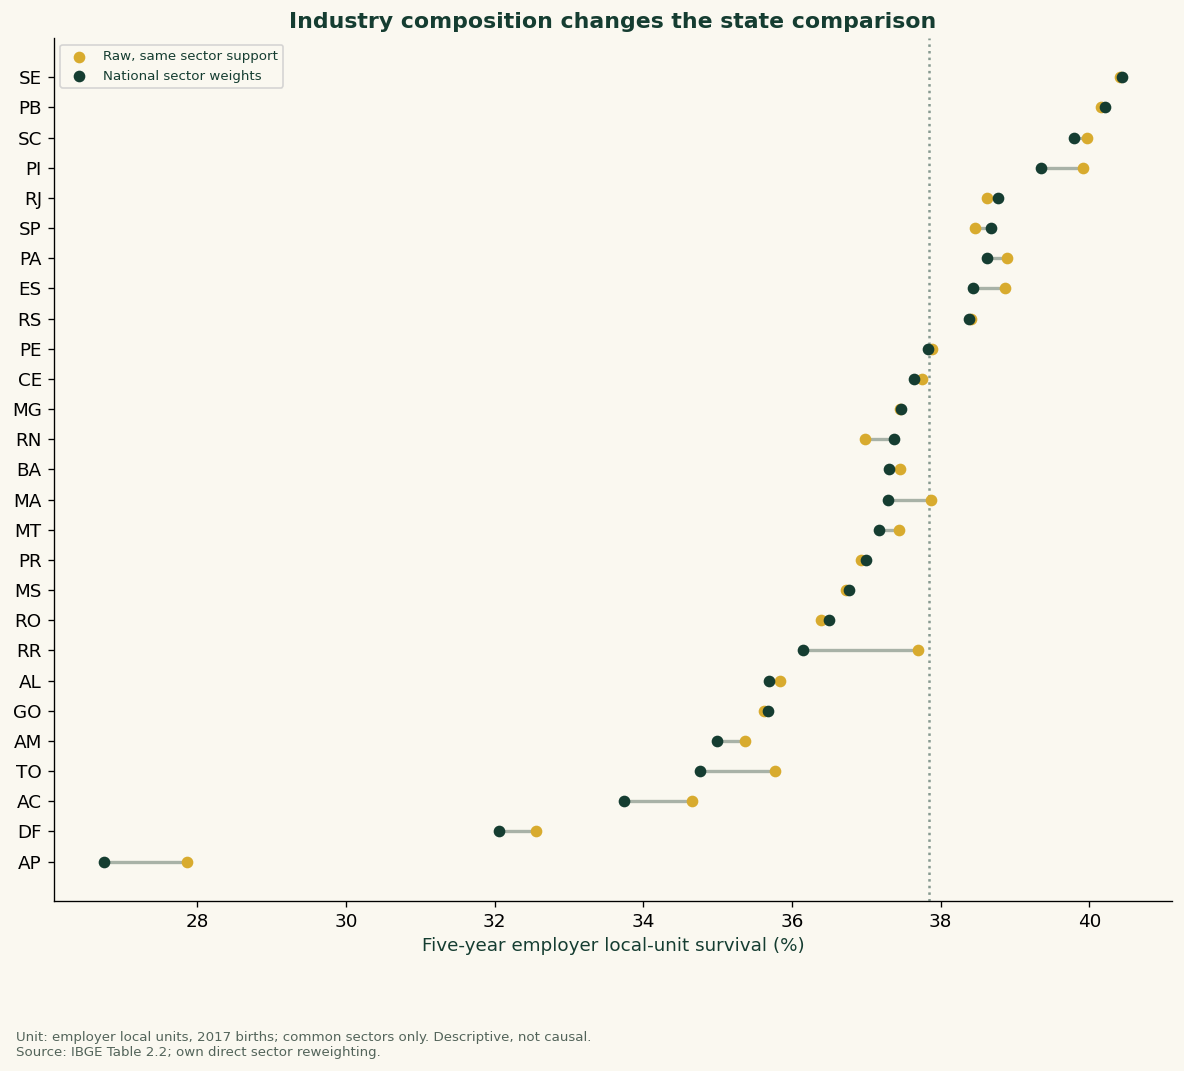

,minimum_births_in_every_state_sector,included_sections,national_common_births,national_cohort_coverage_pct,national_common_five_year_pct,states_with_rank_change_vs_primary,max_absolute_rank_change_vs_primary
0,10,"[C, F, G, H, I, M, N, Q]",263149,88.647128,37.459386,20,4
1,30,"[C, F, G, I, Q]",215396,72.560552,37.220283,21,8


Minimum state-sector births: 10


,uf,common_births,state_cohort_coverage_pct,standardised_five_year_pct,standardised_rank,rank_change_vs_primary_standardisation
14,SE,1969,86.587511,39.981991,1,0
21,SC,15652,89.373608,39.795949,2,1
11,PB,3146,88.395617,39.468533,3,-1
8,PI,2721,90.428714,39.240147,4,0
19,SP,68676,88.225999,38.378019,5,1
18,RJ,17032,86.911262,38.181922,6,-1
22,RS,18026,89.127318,38.080538,7,2
4,PA,5331,89.747475,37.647936,8,-1
17,ES,5450,88.102166,37.335886,9,-1
16,MG,28504,88.579508,37.172766,10,2


Minimum state-sector births: 30


,uf,common_births,state_cohort_coverage_pct,standardised_five_year_pct,standardised_rank,rank_change_vs_primary_standardisation
8,PI,2409,80.059821,40.190895,1,3
14,SE,1603,70.492524,39.979256,2,-1
11,PB,2744,77.100309,39.387869,3,-1
21,SC,12825,73.231314,39.226892,4,-1
19,SP,54624,70.173816,38.422805,5,1
22,RS,14655,72.459827,38.056676,6,3
18,RJ,13981,71.342552,37.413484,7,-2
17,ES,4546,73.488522,37.210891,8,0
4,PA,4530,76.262626,37.091359,9,-2
16,MG,23077,71.714472,37.050599,10,2


In [12]:
standardisation = ibge['sector_standardisation']
standardised = pd.DataFrame(ibge['standardised_states'])
display(pd.Series({k:v for k,v in standardisation.items() if not isinstance(v,(list,dict))},name='Standardisation support').to_frame())
display(pd.DataFrame({'section':list(standardisation['weights_pct']), 'national_weight_pct':list(standardisation['weights_pct'].values())}))
columns = ['uf','name','full_births','common_births','state_cohort_coverage_pct','min_included_sector_births','raw_full_five_year_pct','raw_common_five_year_pct','standardised_five_year_pct','composition_shift_pp','rank_change_vs_raw_common']
display(standardised[columns].sort_values('standardised_five_year_pct',ascending=False))
assert abs(sum(standardisation['weights_pct'].values())-100) < .00001
for row in ibge['standardised_states']:
    recomputed = sum(r['national_weight_pct']*r['five_year_survival_pct']/100 for r in row['sector_support'])
    assert abs(recomputed-row['standardised_five_year_pct']) < 1e-9
s = standardised.sort_values('standardised_five_year_pct')
fig, ax = plt.subplots(figsize=(10,9))
y = np.arange(len(s))
ax.hlines(y,s['raw_common_five_year_pct'],s['standardised_five_year_pct'],color='#a8b2a7',linewidth=2)
ax.scatter(s['raw_common_five_year_pct'],y,color=YELLOW,label='Raw, same sector support',zorder=3)
ax.scatter(s['standardised_five_year_pct'],y,color=GREEN,label='National sector weights',zorder=3)
ax.set_yticks(y, s['uf'])
ax.axvline(standardisation['national_common_five_year_pct'],color=GREEN,linestyle=':',alpha=.5)
ax.set(xlabel='Five-year employer local-unit survival (%)',title='Industry composition changes the state comparison')
ax.legend(fontsize=8)
finish(fig,'ibge-sector-standardisation','IBGE Table 2.2; own direct sector reweighting.','Unit: employer local units, 2017 births; common sectors only. Descriptive, not causal.')
summary_keys = ['minimum_births_in_every_state_sector','included_sections','national_common_births','national_cohort_coverage_pct','national_common_five_year_pct','states_with_rank_change_vs_primary','max_absolute_rank_change_vs_primary']
display(pd.DataFrame([{k:r[k] for k in summary_keys} for r in standardisation['sensitivity_analyses']]))
for sensitivity in standardisation['sensitivity_analyses']:
    print('Minimum state-sector births:',sensitivity['minimum_births_in_every_state_sector'])
    display(pd.DataFrame(sensitivity['states'])[['uf','common_births','state_cohort_coverage_pct','standardised_five_year_pct','standardised_rank','rank_change_vs_primary_standardisation']].sort_values('standardised_rank'))

The stricter support checks require at least 10 or 30 births in every state's included sector cells, recomputing national weights on each support. This drops national cohort coverage to approximately 88.6% and 72.6%. Ranks can change substantially as the estimand changes; compare rates and denominators as well as ranks. These checks reveal small-cell/support sensitivity, not statistical confidence intervals. Exact values and state results are retained in the structured source extract.

## Sensitivity to the population definition
Changing the unit changes the denominator and the meaning of the outcome. The small numerical gap between the two published Brazil rates is not a correction factor to apply to CNPJ active shares. The populations differ in employer coverage, unit structure, entry rules, calendar period and survival definition. Keep each estimate attached to its own denominator.

No individual adjustment, predictive calibration, municipality-level estimate or location-causal model is claimed. Published subgroup differences identify questions for future research, not a reliable forecast for a particular founder.

In [13]:
comparison = pd.DataFrame([
    {'population':'CNPJ registered establishments','denominator':national['establishments'],'measure':'Current active registration share (%)','value':national['active_share']*100},
    {'population':'IBGE employer enterprise births, 2017','denominator':ibge['national']['births'],'measure':'Five consecutive years as employer (%)','value':ibge['national']['five_year_survival_pct']},
    {'population':'IBGE employer local-unit births, 2017','denominator':ibge['local_units_national']['births'],'measure':'Five consecutive years as employer (%)','value':ibge['local_units_national']['five_year_survival_pct']}
])
display(comparison)
print('Difference between IBGE local-unit and enterprise rates:', round(comparison.iloc[2]['value']-comparison.iloc[1]['value'],3),'percentage points')

,population,denominator,measure,value
0,CNPJ registered establishments,73809379,Current active registration share (%),38.451283
1,"IBGE employer enterprise births, 2017",261302,Five consecutive years as employer (%),37.318890
2,"IBGE employer local-unit births, 2017",296850,Five consecutive years as employer (%),37.853800


Difference between IBGE local-unit and enterprise rates: 0.535 percentage points


## Six questions for readers
1. Out of 100 entrants to the employer population, how many remain after one, three and five years?
2. When is the largest drop-off, and what is the annual attrition rate among those still in the surviving cohort?
3. Does reaching year one improve the conditional outlook for reaching year five?
4. Which industries have higher and lower observed survival, and how large were their cohorts?
5. How does my state compare nationally, within an industry and under different support rules?
6. Does an active registration mean a business is operating continuously? No: CNPJ administrative status and IBGE employer survival answer different questions.

### Time: risk sets, conditional survival and evidence boundaries
Let S(t) be the published percentage of the original enterprise cohort surviving through age t. Annual attrition is **100 × [1 − S(t)/S(t−1)]**, conditional on still belonging to the surviving cohort at t−1. Original-cohort loss is **S(t−1) − S(t)** percentage points. Conditional survival to year five is **100 × S(5)/S(t)**. The year-five value is mechanically 100%; it is not a forecast of surviving another five years.

Rates are derived from rounded published percentages. We do not reconstruct integer events or confidence intervals. They describe this historical employer cohort, not causal improvements from ageing. Reaching a later year selects a different risk set.

,age,year,survival_pct,annual_attrition_pct,original_cohort_loss_pp,conditional_to_horizon_pct,horizon_age
0,0,2017,100.00000,NaN,NaN,37.318890,5
1,1,2018,76.21603,23.783970,23.78397,48.964621,5
2,2,2019,59.63253,21.758546,16.58350,62.581430,5
3,3,2020,49.36434,17.219108,10.26819,75.598884,5
4,4,2021,42.27752,14.356153,7.08682,88.271237,5
5,5,2022,37.31889,11.728763,4.95863,100.000000,5


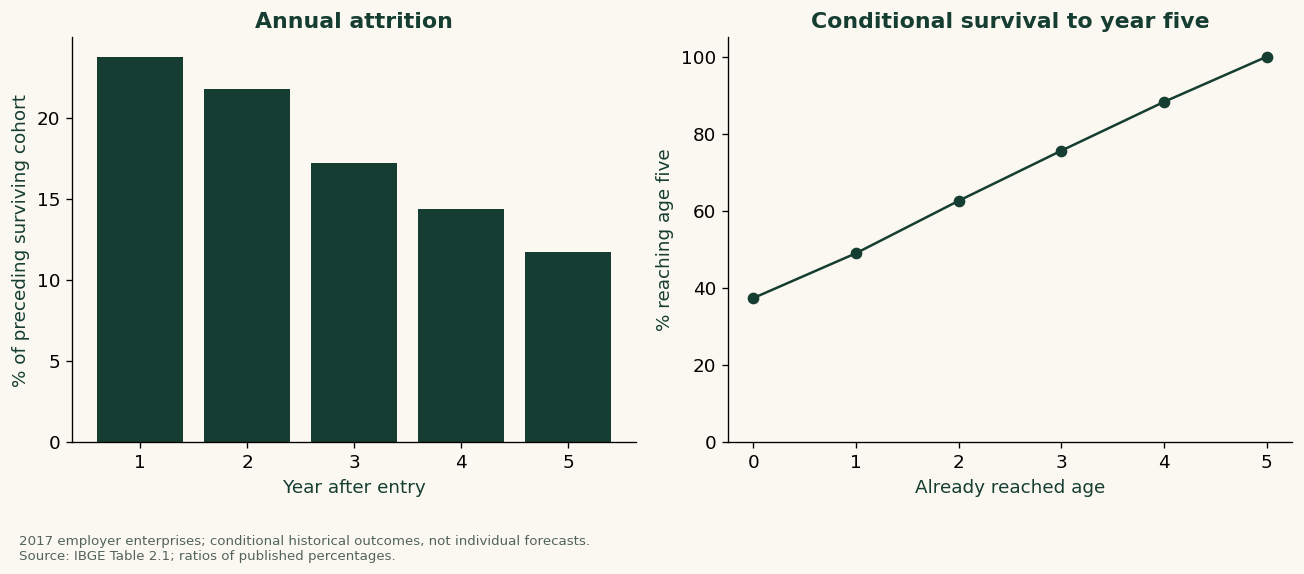

,question,status,needed
0,Do later entry cohorts follow the same traject...,Not identified by the imported tables,Comparable later entry cohorts at matched ages...
1,What if survival means retaining a registratio...,No comparable registration-survival history in...,"Longitudinal registrations with explicit exit,..."


In [14]:
depth_namespace = {'__name__':'notebook_depth','__file__':str(ROOT/'research/deepen.py')}
exec(compile((ROOT/'research/deepen.py').read_text(encoding='utf-8'),'deepen.py','exec'),depth_namespace)
depth = depth_namespace['derive'](ibge)
assert depth == story['depth'], 'Rebuild derived aggregates before running the notebook.'
time = pd.DataFrame(depth['time'])
display(time)
assert np.isclose(np.prod(1-time['annual_attrition_pct'].dropna()/100)*100,time.iloc[-1]['survival_pct'])
assert np.isclose(time.iloc[1]['conditional_to_horizon_pct'],100*time.iloc[-1]['survival_pct']/time.iloc[1]['survival_pct'])
fig, axes = plt.subplots(1,2,figsize=(11,4.8))
axes[0].bar(time['age'][1:],time['annual_attrition_pct'][1:],color=GREEN)
axes[0].set(xlabel='Year after entry',ylabel='% of preceding surviving cohort',title='Annual attrition')
axes[1].plot(time['age'],time['conditional_to_horizon_pct'],marker='o',color=GREEN)
axes[1].set(xlabel='Already reached age',ylabel='% reaching age five',ylim=(0,105),title='Conditional survival to year five')
finish(fig,'ibge-time-risk-sets','IBGE Table 2.1; ratios of published percentages.','2017 employer enterprises; conditional historical outcomes, not individual forecasts.')
display(pd.DataFrame(depth['evidence_gaps']))

### Within-industry state comparisons
Every comparison below uses employer local units, the same 2017 entry cohort and the same CNAE section. A national industry benchmark comes from Table 2.2, not the enterprise table. Zero-birth cells have undefined rates. Positive small cells are retained in the data and can be filtered in the website; exclusions and retained coverage must remain visible. No municipality, employment-size adjustment or causal location effect is identified.

,section,industry,national_five_year_pct,uf,name,births,five_year_survival_pct,source_row
0,A,"A Agricultura, pecuária, produção florestal, p...",43.06202,RO,Rondônia,15,46.66667,49
1,A,"A Agricultura, pecuária, produção florestal, p...",43.06202,AC,Acre,8,37.50000,70
2,A,"A Agricultura, pecuária, produção florestal, p...",43.06202,AM,Amazonas,6,0.00000,91
3,A,"A Agricultura, pecuária, produção florestal, p...",43.06202,RR,Roraima,1,0.00000,112
4,A,"A Agricultura, pecuária, produção florestal, p...",43.06202,PA,Pará,68,51.47059,133
...,...,...,...,...,...,...,...,...
508,S,S Outras atividades de serviços,30.89721,RS,Rio Grande do Sul,433,28.40647,592
509,S,S Outras atividades de serviços,30.89721,MS,Mato Grosso do Sul,132,36.36364,634
510,S,S Outras atividades de serviços,30.89721,MT,Mato Grosso,118,34.74576,655
511,S,S Outras atividades de serviços,30.89721,GO,Goiás,213,32.39437,676


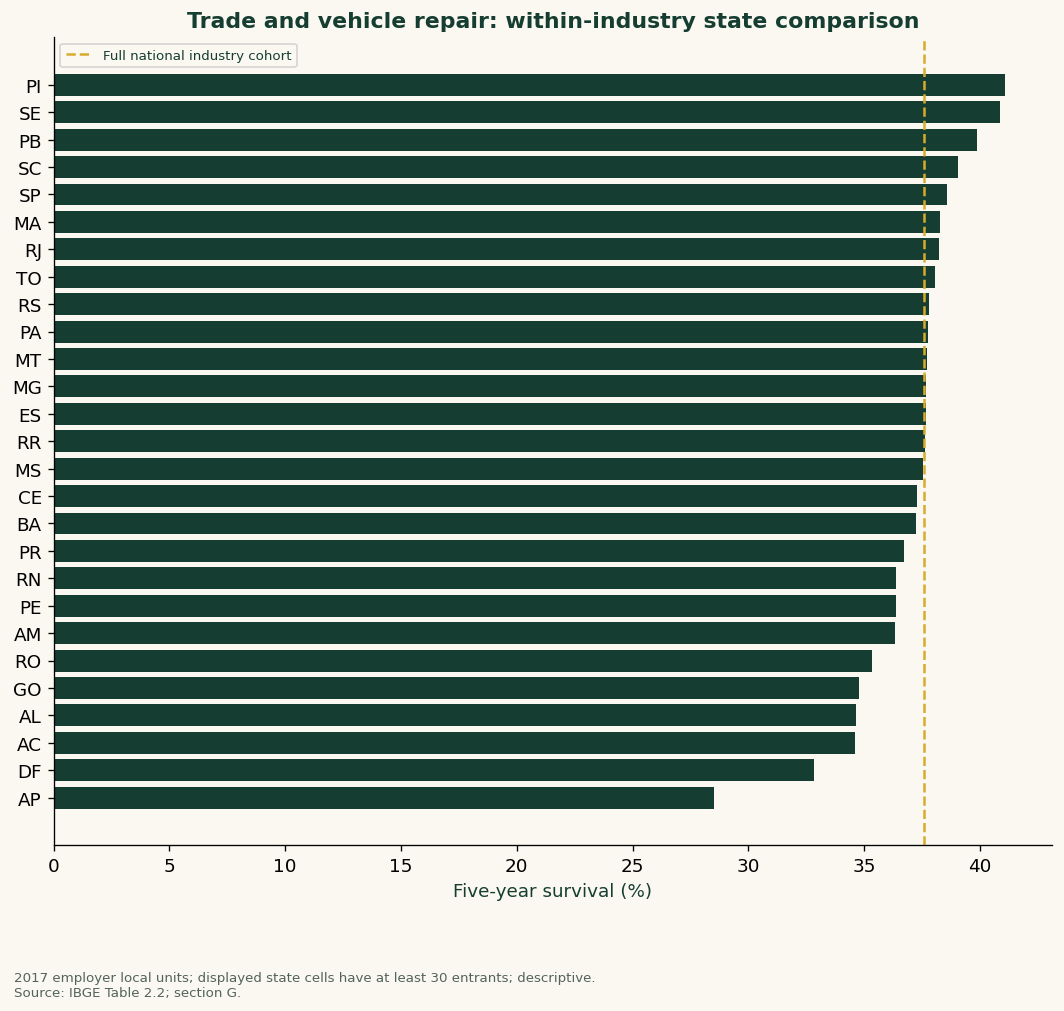

In [15]:
within = pd.DataFrame([{'section':s['section'],'industry':s['label'],'national_five_year_pct':s['national_five_year_pct'],**r} for s in depth['within_industry'] for r in s['states']])
display(within)
assert within.shape[0] == 27*len(depth['within_industry'])
example = within[within['section'].eq('G') & within['births'].ge(30)].sort_values('five_year_survival_pct')
fig, ax = plt.subplots(figsize=(9,8.5))
ax.barh(example['uf'],example['five_year_survival_pct'],color=GREEN)
ax.axvline(example['national_five_year_pct'].iloc[0],color=YELLOW,linestyle='--',label='Full national industry cohort')
ax.set(xlabel='Five-year survival (%)',title='Trade and vehicle repair: within-industry state comparison')
ax.legend(fontsize=8)
finish(fig,'ibge-within-industry-states','IBGE Table 2.2; section G.','2017 employer local units; displayed state cells have at least 30 entrants; descriptive.')

### Ranking sensitivity: compare the assumptions too
The primary common support includes positive-birth sectors in every state. Requiring at least 10 or 30 entrants in every state-sector cell changes the included industries, cohort coverage, weights and therefore the estimand. A changed rank is a sensitivity result, not evidence that a state's underlying performance changed. These rank ranges are **not confidence intervals**. Rank 1 means the highest rate under that particular specification.

,uf,name,standardised_rank,standardised_five_year_pct,common_births,min_included_sector_births,rank_min_10,rate_min_10,coverage_min_10_pct,rank_min_30,rate_min_30,coverage_min_30_pct,max_rank_movement
14,SE,Sergipe,1,40.431909,2272,4,1,39.981991,86.587511,2,39.979256,70.492524,1
11,PB,Paraíba,2,40.213885,3559,6,3,39.468533,88.395617,3,39.387869,77.100309,1
21,SC,Santa Catarina,3,39.796231,17497,23,2,39.795949,89.373608,4,39.226892,73.231314,1
8,PI,Piauí,4,39.350918,3009,7,4,39.240147,90.428714,1,40.190895,80.059821,3
18,RJ,Rio de Janeiro,5,38.775424,19579,32,6,38.181922,86.911262,7,37.413484,71.342552,2
19,SP,São Paulo,6,38.670268,77775,42,5,38.378019,88.225999,5,38.422805,70.173816,1
4,PA,Pará,7,38.615573,5925,12,8,37.647936,89.747475,9,37.091359,76.262626,2
17,ES,Espírito Santo,8,38.428297,6172,22,9,37.335886,88.102166,8,37.210891,73.488522,1
22,RS,Rio Grande do Sul,9,38.382679,20216,31,7,38.080538,89.127318,6,38.056676,72.459827,3
12,PE,Pernambuco,10,37.827168,9280,11,11,37.089257,88.797932,15,36.554538,75.376993,5


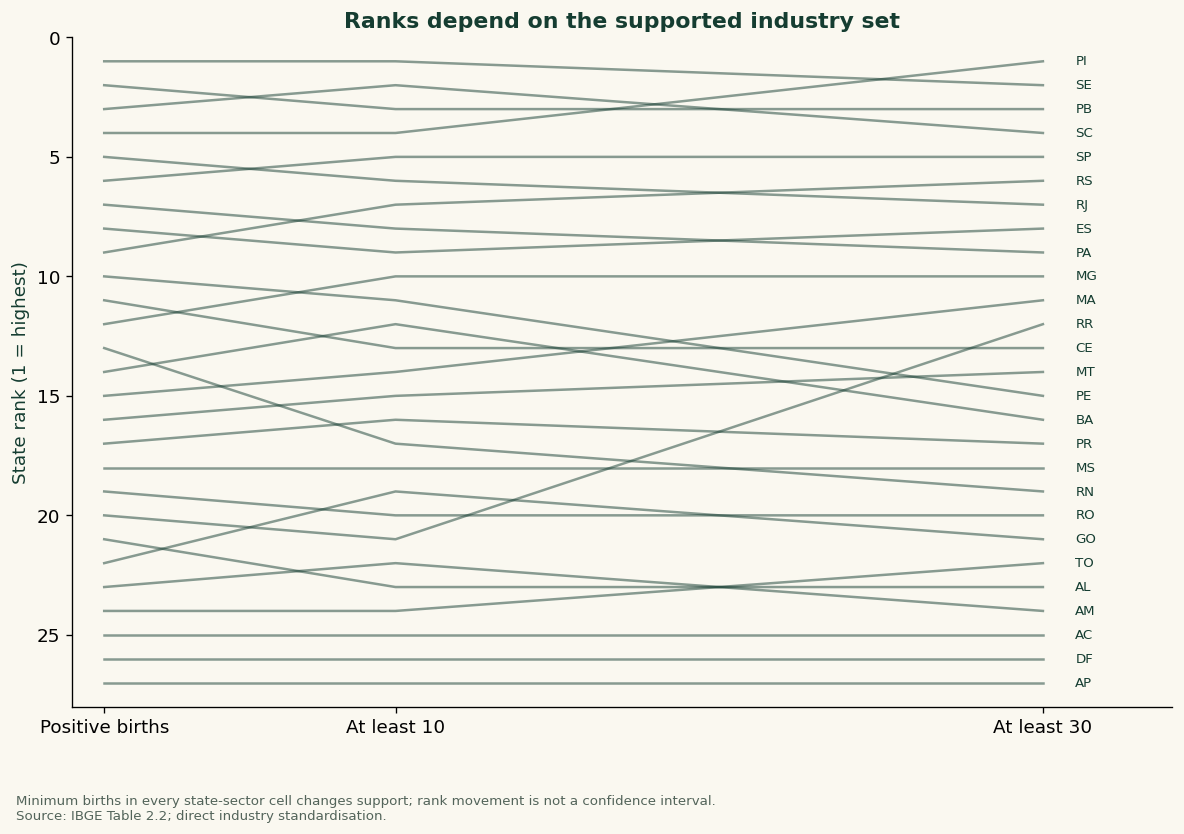

In [16]:
ranking = pd.DataFrame(depth['ranking_sensitivity']).sort_values('standardised_rank')
display(ranking)
for threshold in [10,30]:
    assert sorted(ranking[f'rank_min_{threshold}']) == list(range(1,28))
fig, ax = plt.subplots(figsize=(10,7))
for row in ranking.itertuples():
    ax.plot([1,10,30],[row.standardised_rank,row.rank_min_10,row.rank_min_30],alpha=.5,color=GREEN)
    ax.text(31,row.rank_min_30,row.uf,fontsize=8,va='center')
ax.set(xticks=[1,10,30],xticklabels=['Positive births','At least 10','At least 30'],ylabel='State rank (1 = highest)',title='Ranks depend on the supported industry set',ylim=(28,0),xlim=(0,34))
finish(fig,'ibge-rank-sensitivity','IBGE Table 2.2; direct industry standardisation.','Minimum births in every state-sector cell changes support; rank movement is not a confidence interval.')

## Findings and boundaries
The complete CNPJ release supports a national description of registered economic structure: administrative status, geographic scale, primary activity, opening cohorts and company profiles. All dimension totals must reconcile to the underlying population. Its active shares remain snapshot statistics, even when grouped by opening year.

IBGE supplies the defensible five-year claim: approximately **37.3% of the 2017 employer-enterprise cohort remained employers through all five observation years**. Size and industry comparisons share that enterprise denominator; state comparisons use a separate local-unit denominator and a 37.9% local-unit Brazil benchmark. Differences remain descriptive. Small denominators, employer transitions and the pandemic period limit interpretation.

The appropriate next step is a longitudinal design with sufficient historical follow-up and explicit event definitions. Until then, presenting a fitted five-year CNPJ model would add apparent precision without identification.

### Sources and artifacts
Original official URLs and SHA-256 records are shown above and retained in `data/ibge/survival.json` and acquisition manifests. IBGE definitions and caveats are retained verbatim in the structured extract below. Tables in `data/analysis-tables/` and PNGs in `assets/notebook/` support review and reuse.

In [17]:
display(pd.Series(ibge['definitions'],name='IBGE definitions').to_frame())
for limitation in ibge['limitations']:
    print('•',limitation)
print('Exported figures:', ', '.join(p.name for p in sorted(FIGURES.glob('*.png'))))
print('Aggregate CSV tables:', ', '.join(p.name for p in sorted((ROOT/'data'/'analysis-tables').glob('*.csv'))))

,IBGE definitions
employer_enterprises,Enterprises with at least one salaried employe...
employer_local_units,Employer establishments/local units; distinct ...
birth,"Employer births include new activity, activity..."
survival,Active as an employer in birth year and each c...
births,Published 2017 cohort denominator for the same...
size,Published salaried-personnel bands; associatio...
curve,"Published percentages for ages 1-5, fixed 2017..."
symbols,"{'-': 'exact numeric zero, not rounding', 'x':..."


• Published aggregate tables provide no individual enterprise histories, municipality survival estimates, founder covariates, or fitted adjusted survival model.
• State rankings describe employer local units, while national enterprise sector/size comparisons describe employer enterprises; do not combine their denominators.
• Five-year rates cover the pandemic period but alone do not identify a causal pandemic effect.
• Rates retain workbook precision; publication text typically rounds to one decimal. No invented uncertainty intervals or reconstructed survivor counts.
• Small sector denominators require care: electricity/gas has 119 enterprise births, public administration 7; display denominators alongside comparisons.
• PDF size-section heading says local units, but its body and Chart 3 say enterprises; Table 2.1 size groups sum to the 261302-enterprise cohort. Table 2.1 title contains extraneous salary/age wording; extracted columns are births and survival rates only.
Exported figures